# Regression Modeling

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
housing = pd.read_csv("../data/raw/housing.csv")
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
housing.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

### Why fit the imputer on the training data?

For a fair estimate of how a model will perform on unseen data, split the data before learning preprocessing values. Calculate the median for each numeric feature from the training set only, then use that same training-set median to fill missing values in both the training and test sets. Calculating the median from the entire dataset would let information from the test set influence preprocessing; this is a form of data leakage and can make evaluation less reliable. In cross-validation, the imputer should be fitted separately within each training fold, typically by placing it in a scikit-learn `Pipeline`.

The test set is still imputed—it is transformed using the median learned from training, rather than a separately calculated test median. Median imputation is a reasonable choice for numeric features when a simple fill is needed, especially when values may be skewed or affected by outliers, but it is not mandatory for every dataset or model. Choose an appropriate strategy based on the feature distributions and modeling needs. If you are only doing descriptive analysis and not evaluating a model on held-out data, using all available rows to calculate a summary statistic may be acceptable; it is the predictive evaluation workflow that requires fitting preprocessing on training data only.

In [4]:
# Reproduce the feature engineered variables from the previous notebook

housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_per_room"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["population_per_household"] = housing["population"] / housing["households"]
housing["income_x_rooms_per_household"] = housing["median_income"] * housing["rooms_per_household"]

These features represent:

- rooms_per_household: average number of rooms per household.
- bedrooms_per_room: proportion of rooms that are bedrooms.
- population_per_household: average population per household.
- income_x_rooms_per_household: interaction between median income and average rooms per household.

The interaction feature allows the model to represent a combined effect of income and housing size, rather than treating them as entirely independent.

### Split the data

In [5]:
X = housing.drop(columns=["median_house_value"])
y = housing["median_house_value"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (16512, 13)
Testing features: (4128, 13)


## Build Preprocessing Pipeline

### Identify feature types

In [7]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms_per_household']
Categorical features: ['ocean_proximity']


### Numerical Processing

What happens here?

1. SimpleImputer calculates the median of each numerical feature using training data only.
2. Missing values in the training and test sets are filled using those training medians.
3. StandardScaler learns the training means and standard deviations.
4. Both training and test values are transformed using those same learned parameters.

This is how we prevent preprocessing leakage.

In [8]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

### Categorical Preprocessing

Why One-Hot Encoding?

ocean_proximity contains categories such as INLAND, NEAR BAY, and NEAR OCEAN. Assigning arbitrary numbers to these categories could incorrectly imply that one category is numerically greater than another.

One-Hot Encoding creates separate binary columns instead.

In [9]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

### Combine the two pipelines

In [10]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

## Establish baseline and train the model

### 1. Baseline model



In [11]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="mean"))
])

baseline_model.fit(X_train, y_train)

#NOTE: The DummyRegressor is a regressor that makes predictions using simple rules. It is useful as a simple baseline to compare with other (real) regressors. Do not use it for real problems!!!

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['longitude','latitude','housing_median_age',...,'bedrooms_per_room', 'population_per_household','income_x_rooms_per_household']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` wil

### 2. OLS Regression

The OLS cell creates a scikit-learn Pipeline with two steps:

- preprocessor: fills missing values, scales numeric features, and one-hot encodes categorical features.
- LinearRegression(): fits a linear model to predict house values.

Calling ols_model.fit(X_train, y_train) learns the preprocessing transformations from the training features, then fits the regression coefficients to the transformed training data. OLS chooses coefficients that minimize the sum of squared differences between the model’s predictions and the actual house values. It gives you a straightforward baseline, though correlated features can make individual coefficients less stable.

In [12]:
ols_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

ols_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['longitude','latitude','housing_median_age',...,'bedrooms_per_room', 'population_per_household','income_x_rooms_per_household']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` wil

### 3. Ridge regression

The Ridge cell uses the same preprocessing, followed by Ridge(). Ridge is also a linear regressor, but it adds a penalty that discourages large coefficients. This can make the fitted coefficients more stable when predictors overlap. Unlike Lasso, Ridge generally shrinks coefficients rather than setting some exactly to zero.

The rest of the cell searches for a useful penalty strength:

- ridge_params tests 13 alpha values from 0.001 to 1000. Larger alpha means stronger regularization.
- GridSearchCV(..., cv=5) evaluates each value using five-fold cross-validation on the training data.
- scoring="neg_root_mean_squared_error" selects based on RMSE. Scikit-learn represents losses as negative scores, so the code negates best_score_ when printing the RMSE.
- ridge_search.fit(X_train, y_train) runs the search, and best_estimator_ stores the best-performing fitted pipeline.

Because preprocessing is inside each pipeline, cross-validation fits it separately within each training fold, helping avoid information leakage. The printed Ridge RMSE is a cross-validation score; a final comparison still needs predictions and metrics on the held-out test set.

In [13]:
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

ridge_params = {
    "model__alpha": np.logspace(-3, 3, 13)
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

best_ridge_model = ridge_search.best_estimator_

print("Best Ridge alpha:", ridge_search.best_params_)
print("Best Ridge CV RMSE:", -ridge_search.best_score_)

Best Ridge alpha: {'model__alpha': np.float64(1.0)}
Best Ridge CV RMSE: 67759.02876520125


### 4. Lasso Regression

The Lasso cell follows the same pipeline-and-search pattern as Ridge: it preprocesses the data, fits a regression model, and uses cross-validation to choose a regularization strength.

- Lasso(max_iter=20000) fits a linear model with an L1 penalty. Like Ridge, it shrinks coefficients; unlike Ridge, Lasso can shrink some coefficients all the way to zero. This can act as a form of feature selection. max_iter=20000 allows extra optimization iterations to help the model converge.
- lasso_params tests the same 13 alpha values as Ridge, from 0.001 to 1000.
- GridSearchCV(..., cv=5, scoring="neg_root_mean_squared_error") selects the alpha with the lowest average RMSE across five training folds.
- lasso_search.fit(X_train, y_train) runs the search. best_lasso_model stores the best fitted pipeline, and the print statements show the selected alpha and its cross-validation RMSE.

In [14]:
lasso_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=20000))
])

lasso_params = {
    "model__alpha": np.logspace(-3, 3, 13)
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

best_lasso_model = lasso_search.best_estimator_

print("Best Lasso alpha:", lasso_search.best_params_)
print("Best Lasso CV RMSE:", -lasso_search.best_score_)

Best Lasso alpha: {'model__alpha': np.float64(3.1622776601683795)}
Best Lasso CV RMSE: 67760.23040274433


## Evaluation and Comparison of Models

In [20]:
# GENERATE PREDICTIONS FOR ALL MODELS

models = {
    "Baseline": baseline_model,
    "OLS": ols_model,
    "Ridge": best_ridge_model,
    "Lasso": best_lasso_model
}

predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)



In [21]:
# CALCULATE EVALUATION METRICS FOR ALL MODELS

results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values(by="RMSE")

display(results_df.round(4))

,Model,RMSE,MAE,R2
1,OLS,68917.3167,49709.5395,0.6375
3,Lasso,68921.8257,49711.8528,0.6375
2,Ridge,68925.9572,49715.8408,0.6375
0,Baseline,114485.6354,90606.8549,-0.0002


### How to interpret the metrics

- **RMSE (Root Mean Squared Error):** Typical prediction error in the target's units, with larger errors penalized more heavily. Lower is better; compare models on the same test set and prefer the smaller RMSE when large misses matter.
- **MAE (Mean Absolute Error):** Average absolute difference between predicted and actual house values, also in dollars. Lower is better and gives a straightforward sense of the typical error.
- **R² (Coefficient of Determination):** How much of the variation in test-set house values the model explains relative to predicting the test-set mean. Closer to 1 is better; 0 is about as good as that mean-prediction baseline, and a negative value is worse than the baseline.

Use the held-out test results to compare models: generally favor lower RMSE and MAE with higher R², while considering whether the error size is acceptable for the intended use. The baseline provides a useful reference for whether the trained models improve on a simple mean prediction.

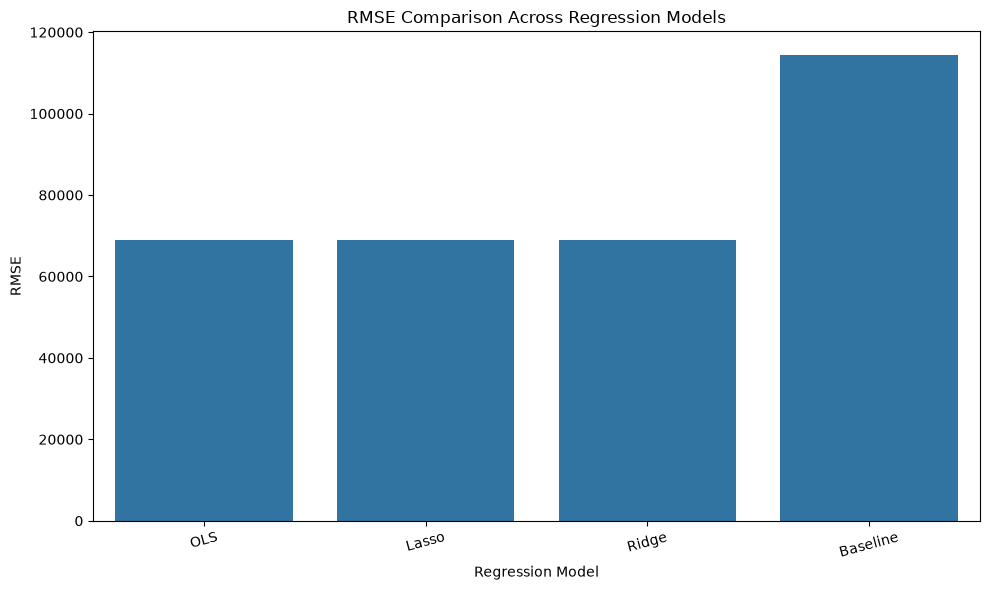

In [22]:
# VISUALIZE MODEL PERFORMANCE

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison Across Regression Models")
plt.ylabel("RMSE")
plt.xlabel("Regression Model")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

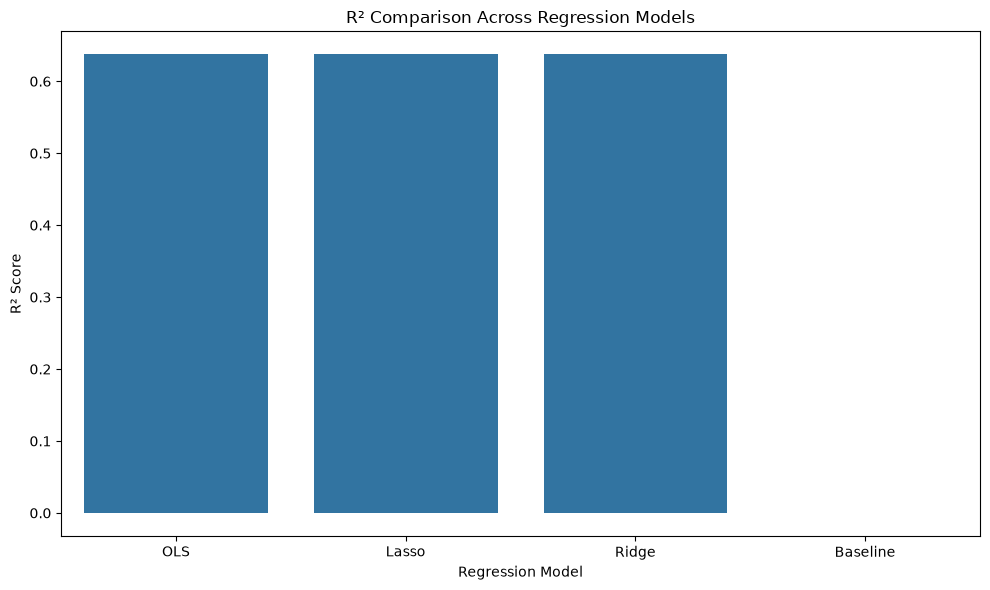

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2"
)

plt.title("R² Comparison Across Regression Models")
plt.ylabel("R² Score")
plt.xlabel("Regression Model")
plt.tight_layout()
plt.show()

## Examine prediction errors


### Select best model

In [24]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
best_predictions = predictions[best_model_name]

print("Best model based on test RMSE:", best_model_name)

Best model based on test RMSE: OLS
